Uploadează mobil123.csv


Saving mobil123.csv to mobil123.csv
✅ mobil123 încărcat: (103230, 11)

Uploadează CarsDatasets2025.csv


Saving CarsDatasets2025.csv to CarsDatasets2025.csv
✅ CarsDatasets2025 încărcat: (1218, 11)

Putere medie din CarsDatasets2025: 250.0 CP
Date după curățare outlieri: (97778, 5)


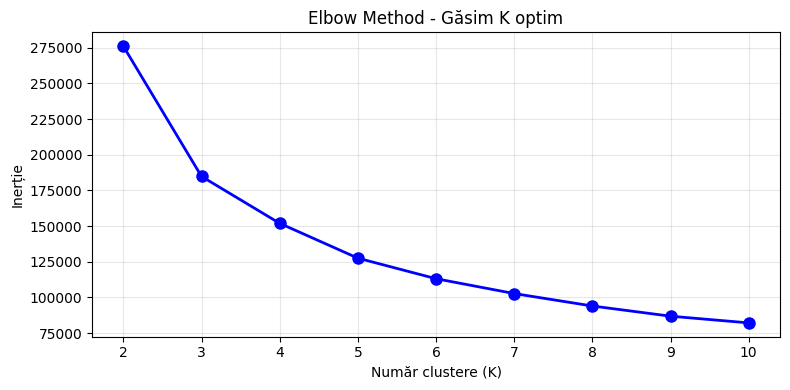


Silhouette Score (K=4): 0.3499
  (0.35–0.65 = bun | aproape de 1 = perfect | negativ = probleme)

=== Media fiecărui cluster ===
         km_clean  motor_clean   pret_clean  an_clean  putere
cluster                                                      
0         38591.0       1376.0  163286417.0    2016.0   250.0
1        100615.0       1772.0  132536644.0    2010.0   250.0
2         22688.0       2517.0  940093114.0    2016.0   250.0
3         54913.0       2361.0  303293550.0    2014.0   250.0

=== Etichete clustere ===
  Cluster 0 → Recente
  Cluster 1 → Economice
  Cluster 2 → Premium
  Cluster 3 → Premium


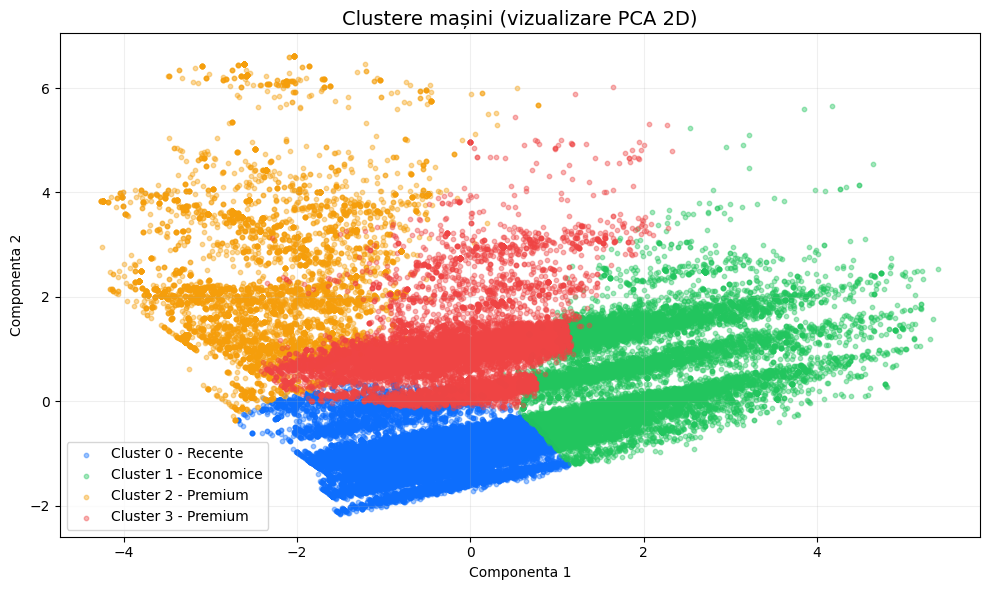

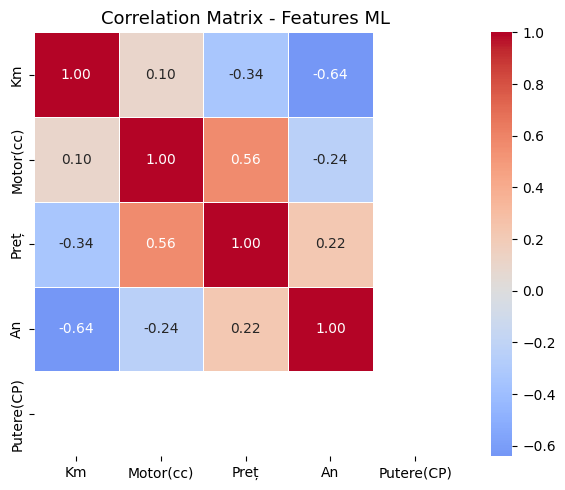


=== CENTROIZI FINALI PENTRU C# ===
[
  {
    "ClusterId": 0,
    "NumeCluster": "Medii",
    "Kilometraj": 38595,
    "CapacitateMotor": 1375,
    "PretEUR": 9303,
    "An": 2016,
    "Putere": 250
  },
  {
    "ClusterId": 1,
    "NumeCluster": "Economice",
    "Kilometraj": 100622,
    "CapacitateMotor": 1772,
    "PretEUR": 7553,
    "An": 2010,
    "Putere": 250
  },
  {
    "ClusterId": 2,
    "NumeCluster": "Premium Recente",
    "Kilometraj": 22686,
    "CapacitateMotor": 2516,
    "PretEUR": 53571,
    "An": 2016,
    "Putere": 250
  },
  {
    "ClusterId": 3,
    "NumeCluster": "Premium Clasice",
    "Kilometraj": 54921,
    "CapacitateMotor": 2360,
    "PretEUR": 17283,
    "An": 2014,
    "Putere": 250
  }
]

CLASIFICARE MAȘINI DIN DB-UL TĂU
Mașina               Preț(€)    An     Km         CP     Cluster
-----------------------------------------------------------------
Audi Q5              78,000     2024   120,000    136    Premium Recente
Audi RS7             75,000     

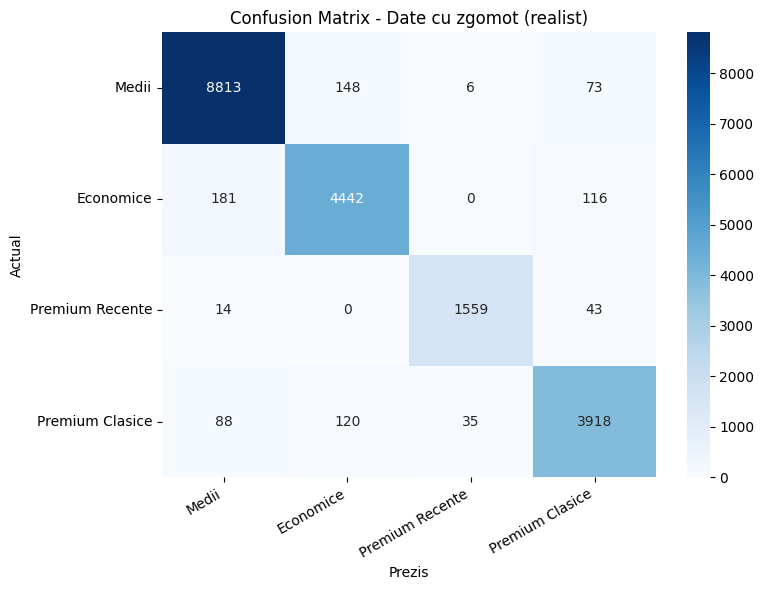


Accuracy fără zgomot: 0.9959
Accuracy cu zgomot:   0.9579
Degradare:            0.0380


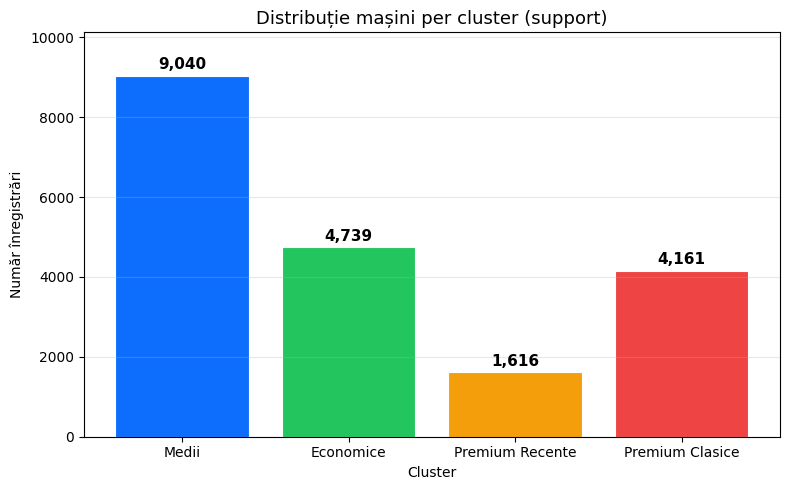


=== Distribuție procentuală ===
  Medii                 9040 (46.2%)
  Economice             4739 (24.2%)
  Premium Recente       1616 (8.3%)
  Premium Clasice       4161 (21.3%)


In [1]:
from google.colab import files
import pandas as pd
import io
import re
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, silhouette_score

# ══════════════════════════════════════════════
# 1. ÎNCĂRCARE DATE
# ══════════════════════════════════════════════
print("Uploadează mobil123.csv")
uploaded1 = files.upload()
df1 = pd.read_csv(io.BytesIO(list(uploaded1.values())[0]), low_memory=False)
print("✅ mobil123 încărcat:", df1.shape)

print("\nUploadează CarsDatasets2025.csv")
uploaded2 = files.upload()
df2 = pd.read_csv(io.BytesIO(list(uploaded2.values())[0]), encoding='latin-1')
print("✅ CarsDatasets2025 încărcat:", df2.shape)

# ══════════════════════════════════════════════
# 2. CURĂȚARE DATE
# ══════════════════════════════════════════════
def parse_mileage(val):
    val = str(val).lower().replace(' ', '')
    if re.search(r'(\d+)-k', val):
        n = int(re.search(r'(\d+)-k', val).group(1))
        return n * 1000
    m = re.search(r'(\d+)-(\d+)k', val)
    if m:
        return (int(m.group(1)) + int(m.group(2))) / 2 * 1000
    n = re.search(r'(\d+)', val)
    return int(n.group(1)) * 1000 if n else np.nan

def parse_eng(val):
    try:
        return float(str(val).replace(',', '.')) * 1000
    except:
        return np.nan

def parse_price_mobil(val):
    try:
        return float(str(val).replace(',', ''))
    except:
        return np.nan

def parse_hp(val):
    val = str(val).lower().replace(' ', '')
    m = re.search(r'(\d+)-(\d+)', val)
    if m:
        return (int(m.group(1)) + int(m.group(2))) / 2
    n = re.search(r'(\d+)', val)
    return float(n.group(1)) if n else np.nan

def parse_cc(val):
    val = str(val).lower().replace(',', '').replace(' ', '')
    n = re.search(r'(\d+)', val)
    return float(n.group(1)) if n else np.nan

df1['km_clean']    = df1['mileage'].apply(parse_mileage)
df1['motor_clean'] = df1['engV'].apply(parse_eng)
df1['pret_clean']  = df1['price'].apply(parse_price_mobil)
df1['an_clean']    = pd.to_numeric(df1['year'], errors='coerce')

df2['putere_clean'] = df2['HorsePower'].apply(parse_hp)
df2['motor_clean']  = df2['CC/Battery Capacity'].apply(parse_cc)

putere_medie = df2['putere_clean'].median()
print(f"\nPutere medie din CarsDatasets2025: {putere_medie} CP")

# ══════════════════════════════════════════════
# 3. PREGĂTIRE DATE ML
# ══════════════════════════════════════════════
df_ml = df1[['km_clean', 'motor_clean', 'pret_clean', 'an_clean']].copy()
df_ml['putere'] = putere_medie
df_ml = df_ml.dropna()

for col in df_ml.columns:
    q_low  = df_ml[col].quantile(0.01)
    q_high = df_ml[col].quantile(0.99)
    df_ml = df_ml[(df_ml[col] >= q_low) & (df_ml[col] <= q_high)]

print(f"Date după curățare outlieri: {df_ml.shape}")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_ml)

# ══════════════════════════════════════════════
# 4. ELBOW METHOD
# ══════════════════════════════════════════════
inertii = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertii.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertii, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Număr clustere (K)')
plt.ylabel('Inerție')
plt.title('Elbow Method - Găsim K optim')
plt.grid(True, alpha=0.3)
plt.xticks(K_range)
plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════
# 5. K-MEANS K=4
# ══════════════════════════════════════════════
K_OPTIM = 4
kmeans = KMeans(n_clusters=K_OPTIM, random_state=42, n_init=10)
kmeans.fit(X_scaled)
df_ml['cluster'] = kmeans.labels_

# ── Silhouette Score ──────────────────────────
sil_score = silhouette_score(X_scaled, kmeans.labels_)
print(f"\nSilhouette Score (K=4): {sil_score:.4f}")
print("  (0.35–0.65 = bun | aproape de 1 = perfect | negativ = probleme)")

cluster_means = df_ml.groupby('cluster').mean().round(0)
print("\n=== Media fiecărui cluster ===")
print(cluster_means)

labels_map = {}
for i, row in cluster_means.iterrows():
    if row['pret_clean'] < cluster_means['pret_clean'].quantile(0.33):
        labels_map[i] = "Economice"
    elif row['pret_clean'] > cluster_means['pret_clean'].quantile(0.66):
        labels_map[i] = "Premium"
    elif row['an_clean'] >= 2016:
        labels_map[i] = "Recente"
    else:
        labels_map[i] = "Clasice"

print("\n=== Etichete clustere ===")
for k, v in labels_map.items():
    print(f"  Cluster {k} → {v}")

# ══════════════════════════════════════════════
# 6. VIZUALIZARE PCA 2D
# ══════════════════════════════════════════════
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

colors = ['#0d6efd', '#22c55e', '#f59e0b', '#ef4444']
plt.figure(figsize=(10, 6))
for i in range(K_OPTIM):
    mask = df_ml['cluster'] == i
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=colors[i], alpha=0.4, s=10,
                label=f"Cluster {i} - {labels_map[i]}")
plt.title('Clustere mașini (vizualizare PCA 2D)', fontsize=14)
plt.xlabel('Componenta 1')
plt.ylabel('Componenta 2')
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════
# 6b. CORRELATION MATRIX
# ══════════════════════════════════════════════
plt.figure(figsize=(7, 5))
corr = df_ml[['km_clean', 'motor_clean', 'pret_clean', 'an_clean', 'putere']].corr()

sns.heatmap(
    corr,
    annot=True, fmt=".2f", cmap='coolwarm',
    center=0, square=True, linewidths=0.5,
    xticklabels=['Km', 'Motor(cc)', 'Preț', 'An', 'Putere(CP)'],
    yticklabels=['Km', 'Motor(cc)', 'Preț', 'An', 'Putere(CP)']
)
plt.title('Correlation Matrix - Features ML', fontsize=13)
plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════
# 7. EXPORT CENTROIZI PENTRU C#
# ══════════════════════════════════════════════
IDR_TO_EUR = 0.000057
centroizi_reali = scaler.inverse_transform(kmeans.cluster_centers_)
centroizi_dict = []
centroizi_final = []

for i, c in enumerate(centroizi_reali):
    centroizi_dict.append({
        "ClusterId": i, "NumeCluster": labels_map[i],
        "Kilometraj": round(c[0], 0), "CapacitateMotor": round(c[1], 0),
        "Pret": round(c[2], 0), "An": round(c[3], 0), "Putere": round(c[4], 0)
    })

for c in centroizi_dict:
    pret_eur = round(c['Pret'] * IDR_TO_EUR, 0)
    if pret_eur < 8000:           nume = "Economice"
    elif pret_eur < 15000:        nume = "Medii"
    elif c['Kilometraj'] < 40000: nume = "Premium Recente"
    else:                         nume = "Premium Clasice"

    centroizi_final.append({
        "ClusterId": c['ClusterId'], "NumeCluster": nume,
        "Kilometraj": int(c['Kilometraj']), "CapacitateMotor": int(c['CapacitateMotor']),
        "PretEUR": int(pret_eur), "An": int(c['An']), "Putere": int(c['Putere'])
    })

print("\n=== CENTROIZI FINALI PENTRU C# ===")
print(json.dumps(centroizi_final, indent=2))

# ══════════════════════════════════════════════
# 8. VERIFICARE PE MAȘINILE DIN DB-UL TĂU
# ══════════════════════════════════════════════
db_data = pd.DataFrame({
    'km_clean':    [120000, 30000, 32000, 50000, 22034, 140000, 32000, 126472, 150249, 70000, 50000, 20000],
    'motor_clean': [2000,   2735,  3500,  2000,  1500,  1990,   2200,  1700,   2000,   2500,  2500,  1800],
    'pret_clean':  [78000,  75000, 120000,35000, 24000, 20000,  100000,20500,  35000,  53000, 32000, 60000],
    'an_clean':    [2024,   2025,  2021,  2019,  2017,  2018,   2024,  2015,   2023,   2021,  2020,  2026],
    'putere':      [136,    380,   430,   150,   120,   190,    210,   150,    350,    220,   300,   210],
    'nume':        ['Audi Q5','Audi RS7','Mercedes CLA','Ford Focus','VW Passat',
                   'Skoda Octavia','Ford Kuga2','Dacia Duster','BMW Seria5',
                   'Toyota Rav4','Chevrolet Camaro','Peugeot 308']
})

EUR_TO_IDR = 1 / IDR_TO_EUR
db_data['pret_idr'] = db_data['pret_clean'] * EUR_TO_IDR

db_scaled_input = db_data[['km_clean', 'motor_clean', 'pret_idr', 'an_clean', 'putere']].copy()
db_scaled_input.columns = ['km_clean', 'motor_clean', 'pret_clean', 'an_clean', 'putere']

for col, mn, mx in zip(
    ['km_clean', 'motor_clean', 'pret_clean', 'an_clean', 'putere'],
    df_ml.min().values,
    df_ml.max().values
):
    db_scaled_input[col] = db_scaled_input[col].clip(mn, mx)

db_scaled = scaler.transform(db_scaled_input)
db_clusters = kmeans.predict(db_scaled)
cluster_id_to_name = {c['ClusterId']: c['NumeCluster'] for c in centroizi_final}

print("\n" + "=" * 65)
print("CLASIFICARE MAȘINI DIN DB-UL TĂU")
print("=" * 65)
print(f"{'Mașina':<20} {'Preț(€)':<10} {'An':<6} {'Km':<10} {'CP':<6} {'Cluster'}")
print("-" * 65)

for i, row in db_data.iterrows():
    cluster_id   = db_clusters[i]
    cluster_name = cluster_id_to_name.get(int(cluster_id), "?")
    print(f"{row['nume']:<20} {row['pret_clean']:<10,.0f} {row['an_clean']:<6.0f} "
          f"{row['km_clean']:<10,.0f} {row['putere']:<6.0f} {cluster_name}")

print("\n=== Distribuție clustere DB ===")
for cid, cname in cluster_id_to_name.items():
    count = sum(1 for c in db_clusters if c == cid)
    print(f"  {cname}: {count} mașini")

# ══════════════════════════════════════════════
# 9. CLASSIFICATION REPORT CU ZGOMOT
# ══════════════════════════════════════════════
X = X_scaled
y = kmeans.labels_

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

np.random.seed(42)
noise = np.random.normal(loc=0, scale=0.15, size=X_test.shape)
X_test_noisy = X_test + noise

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_clean = knn.predict(X_test)
y_pred_noisy = knn.predict(X_test_noisy)

nume_clustere = ['Medii', 'Economice', 'Premium Recente', 'Premium Clasice']

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT - DATE CURATE (referință)")
print("=" * 60)
print(classification_report(y_test, y_pred_clean, target_names=nume_clustere))

print("=" * 60)
print("CLASSIFICATION REPORT - DATE CU ZGOMOT (realist)")
print("=" * 60)
print(classification_report(y_test, y_pred_noisy, target_names=nume_clustere))

cm = confusion_matrix(y_test, y_pred_noisy)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=nume_clustere, yticklabels=nume_clustere)
plt.title('Confusion Matrix - Date cu zgomot (realist)')
plt.ylabel('Actual')
plt.xlabel('Prezis')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

acc_clean = (y_pred_clean == y_test).mean()
acc_noisy = (y_pred_noisy == y_test).mean()
print(f"\nAccuracy fără zgomot: {acc_clean:.4f}")
print(f"Accuracy cu zgomot:   {acc_noisy:.4f}")
print(f"Degradare:            {(acc_clean - acc_noisy):.4f}")

# ══════════════════════════════════════════════
# 10. BAR CHART - DISTRIBUȚIE CLUSTERE (SUPPORT)
# ══════════════════════════════════════════════
cluster_names_ordered = ['Medii', 'Economice', 'Premium Recente', 'Premium Clasice']
support_values        = [9040, 4739, 1616, 4161]
colors_bar = ['#0d6efd', '#22c55e', '#f59e0b', '#ef4444']

plt.figure(figsize=(8, 5))
bars = plt.bar(cluster_names_ordered, support_values, color=colors_bar, edgecolor='white', linewidth=0.8)

for bar, val in zip(bars, support_values):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 80,
             f'{val:,}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title('Distribuție mașini per cluster (support)', fontsize=13)
plt.ylabel('Număr înregistrări')
plt.xlabel('Cluster')
plt.ylim(0, max(support_values) * 1.12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

total = sum(support_values)
print("\n=== Distribuție procentuală ===")
for name, val in zip(cluster_names_ordered, support_values):
    print(f"  {name:<20} {val:>5} ({val/total*100:.1f}%)")